# Caspase vs Mito — All Active Cases: UMAP + DBSCAN

**All three non-inactive cases from the pairwise Caspase vs Mito (HepG2) table:**

| Shape | Case | n | Mechanistic meaning |
|-------|------|---|---------------------|
| ● circle  | Both active       | 144 | Full mitochondrial apoptosis axis |
| ▲ triangle | Casp active, Mito inactive | 17  | Non-mitochondrial caspase activation |
| ■ square  | Casp inactive, Mito active | 972 | Sub-apoptotic mitochondrial disruption |

**Total: 144 + 17 + 972 = 1,133 compounds**

Key question: *do structurally similar compounds share the same mechanistic profile?*  
If yes → clusters will be pure (one shape dominates). If no → clusters are shape-mixed → mechanism is concentration/context-driven, not structure-driven.

Shape = mechanistic case | Color = DBSCAN cluster

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import umap
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from collections import Counter
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'font.size': 10, 'figure.dpi': 120})
print('Libraries loaded.')

Libraries loaded.


## Step 1 — Build CID → SMILES mapping

In [2]:
BASE = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/cleaned_datasets/'

smiles_map = {}
for fname in ['combined_hepg2_casepase.csv', 'AID_720635_cleaned.csv']:
    try:
        df = pd.read_csv(BASE + fname,
                         usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'],
                         low_memory=False)
        df = df.dropna(subset=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'])
        df = df.drop_duplicates('PUBCHEM_CID')
        df['PUBCHEM_CID'] = df['PUBCHEM_CID'].astype(int)
        smiles_map.update(dict(zip(df['PUBCHEM_CID'], df['PUBCHEM_EXT_DATASOURCE_SMILES'])))
    except Exception as e:
        print(f'  Warning [{fname}]: {e}')

print(f'Total CID -> SMILES: {len(smiles_map)}')

Total CID -> SMILES: 8777


## Step 2 — Load activity sets for Caspase (HepG2 combined) and Mito (AID 720635)

In [3]:
def cids_with(path, outcome):
    df = pd.read_csv(path,
                     usecols=['PUBCHEM_CID', 'PUBCHEM_ACTIVITY_OUTCOME'],
                     low_memory=False)
    df = df.dropna(subset=['PUBCHEM_CID', 'PUBCHEM_ACTIVITY_OUTCOME'])
    df['PUBCHEM_CID'] = df['PUBCHEM_CID'].astype(int)
    pri = {'Active': 2, 'Inconclusive': 1, 'Inactive': 0}
    df['_p'] = df['PUBCHEM_ACTIVITY_OUTCOME'].map(pri).fillna(-1)
    df = df.sort_values('_p', ascending=False).drop_duplicates('PUBCHEM_CID')
    return set(df[df['PUBCHEM_ACTIVITY_OUTCOME'] == outcome]['PUBCHEM_CID'])

casp_A = cids_with(BASE + 'combined_hepg2_casepase.csv', 'Active')
casp_I = cids_with(BASE + 'combined_hepg2_casepase.csv', 'Inactive')
mito_A = cids_with(BASE + 'AID_720635_cleaned.csv', 'Active')
mito_I = cids_with(BASE + 'AID_720635_cleaned.csv', 'Inactive')

# Three cases (both-inactive excluded)
case1 = casp_A & mito_A   # both active
case2 = casp_A & mito_I   # caspase active, mito inactive
case3 = casp_I & mito_A   # caspase inactive, mito active

print(f'Case 1 — Both active          (●): {len(case1):>5d}')
print(f'Case 2 — Casp active, Mito-   (▲): {len(case2):>5d}')
print(f'Case 3 — Casp inactive, Mito+ (■): {len(case3):>5d}')
print(f'Total                            : {len(case1)+len(case2)+len(case3):>5d}')
print(f'\nNote: Cases are mutually exclusive by construction — no CID can be in two cases.')

Case 1 — Both active          (●):   144
Case 2 — Casp active, Mito-   (▲):    17
Case 3 — Casp inactive, Mito+ (■):   972
Total                            :  1133

Note: Cases are mutually exclusive by construction — no CID can be in two cases.


## Step 3 — Assign case labels (mutually exclusive by definition)

In [4]:
# Case definitions — mutually exclusive (intersection of Active/Inactive sets)
CASES = [
    ('Case 1', 'Both active',             'o', '#1565C0', case1),  # dark blue circle
    ('Case 2', 'Casp active, Mito inact', '^', '#B71C1C', case2),  # dark red triangle
    ('Case 3', 'Casp inact, Mito active', 's', '#1B5E20', case3),  # dark green square
]

cid_case = {}
for label, desc, marker, color, cids in CASES:
    for cid in cids:
        cid_case[cid] = (label, desc, marker, color)

print(f'Total CIDs labelled: {len(cid_case)}')

Total CIDs labelled: 1133


## Step 4 — Validate SMILES and compute Morgan fingerprints (radius=2, 2048-bit)

In [5]:
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

valid_cids, valid_labels, valid_descs, valid_markers, valid_colors = [], [], [], [], []
fps_list = []

for cid, (label, desc, marker, color) in cid_case.items():
    smi = smiles_map.get(cid)
    if not smi or pd.isna(smi):
        continue
    mol = Chem.MolFromSmiles(str(smi))
    if mol is None:
        continue
    valid_cids.append(cid)
    valid_labels.append(label)
    valid_descs.append(desc)
    valid_markers.append(marker)
    valid_colors.append(color)
    fps_list.append(gen.GetFingerprintAsNumPy(mol))

fps           = np.array(fps_list, dtype=np.uint8)
valid_labels  = np.array(valid_labels)
valid_markers = np.array(valid_markers)
valid_colors  = np.array(valid_colors)

print(f'Valid compounds: {len(valid_cids)}')
print(f'FP matrix shape: {fps.shape}')
for label, desc, *_, cids in CASES:
    n = (valid_labels == label).sum()
    print(f'  {label} ({desc}): {n}')

Valid compounds: 1133
FP matrix shape: (1133, 2048)
  Case 1 (Both active): 144
  Case 2 (Casp active, Mito inact): 17
  Case 3 (Casp inact, Mito active): 972


## Step 5 — UMAP (Jaccard / Tanimoto distance)

In [6]:
print(f'Running UMAP on {len(valid_cids)} compounds...')
reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    metric='jaccard',
    random_state=42,
    n_jobs=1
)
embedding = reducer.fit_transform(fps)
print(f'Embedding shape: {embedding.shape}')

Running UMAP on 1133 compounds...
Embedding shape: (1133, 2)


## Step 6 — k-distance elbow plot to choose DBSCAN eps

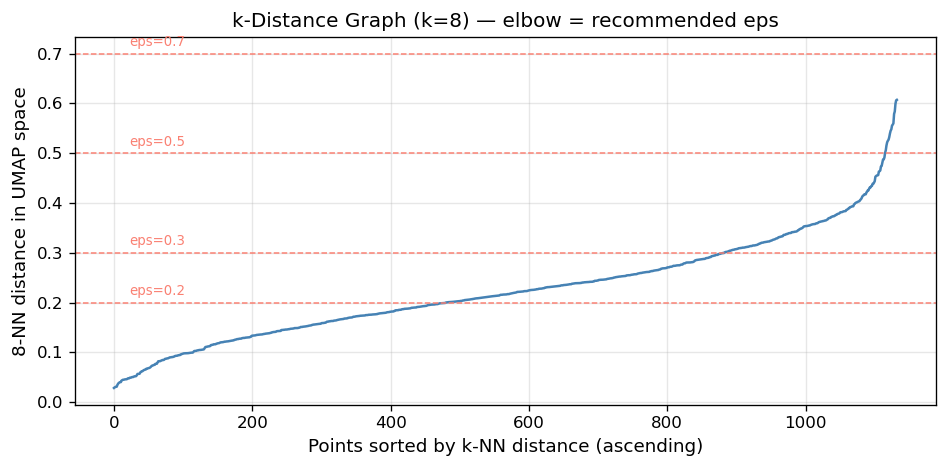

Inspect the elbow, then set EPS in Step 7.


In [7]:
K = 8
nbrs    = NearestNeighbors(n_neighbors=K, metric='euclidean').fit(embedding)
dist, _ = nbrs.kneighbors(embedding)
k_dist  = np.sort(dist[:, K - 1])  # ascending

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_dist, color='steelblue', linewidth=1.5)
ax.set_xlabel('Points sorted by k-NN distance (ascending)', fontsize=11)
ax.set_ylabel(f'{K}-NN distance in UMAP space', fontsize=11)
ax.set_title(f'k-Distance Graph (k={K}) — elbow = recommended eps', fontsize=12)
ax.grid(True, alpha=0.3)
for eps_c in [0.2, 0.3, 0.5, 0.7]:
    ax.axhline(eps_c, color='salmon', linestyle='--', lw=0.9)
    ax.text(len(k_dist) * 0.02, eps_c + 0.015, f'eps={eps_c}', fontsize=8, color='salmon')
plt.tight_layout()
plt.savefig(
    '/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casp_mito_all_kdist_elbow.png',
    dpi=130, bbox_inches='tight'
)
plt.show()
print('Inspect the elbow, then set EPS in Step 7.')

## Step 7 — Fit DBSCAN + silhouette score

In [8]:
EPS         = 0.3   # <-- set from elbow plot
MIN_SAMPLES = 5

db        = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES)
db_labels = db.fit_predict(embedding)

n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise    = (db_labels == -1).sum()
print(f'eps={EPS}, min_samples={MIN_SAMPLES}')
print(f'Clusters : {n_clusters}')
print(f'Noise    : {n_noise}  ({100*n_noise/len(db_labels):.1f}%)')

ok = db_labels >= 0
if ok.sum() > 1 and n_clusters > 1:
    sil = silhouette_score(embedding[ok], db_labels[ok])
    print(f'Silhouette score (non-noise): {sil:.3f}')

eps=0.3, min_samples=5
Clusters : 18
Noise    : 21  (1.9%)
Silhouette score (non-noise): -0.059


## Step 8 — Figure A: UMAP colored by mechanistic case (shape=case, color=case)

Each of the three cases gets a distinct shape AND a distinct color.  
This directly answers: *are the three mechanistic profiles structurally separable?*

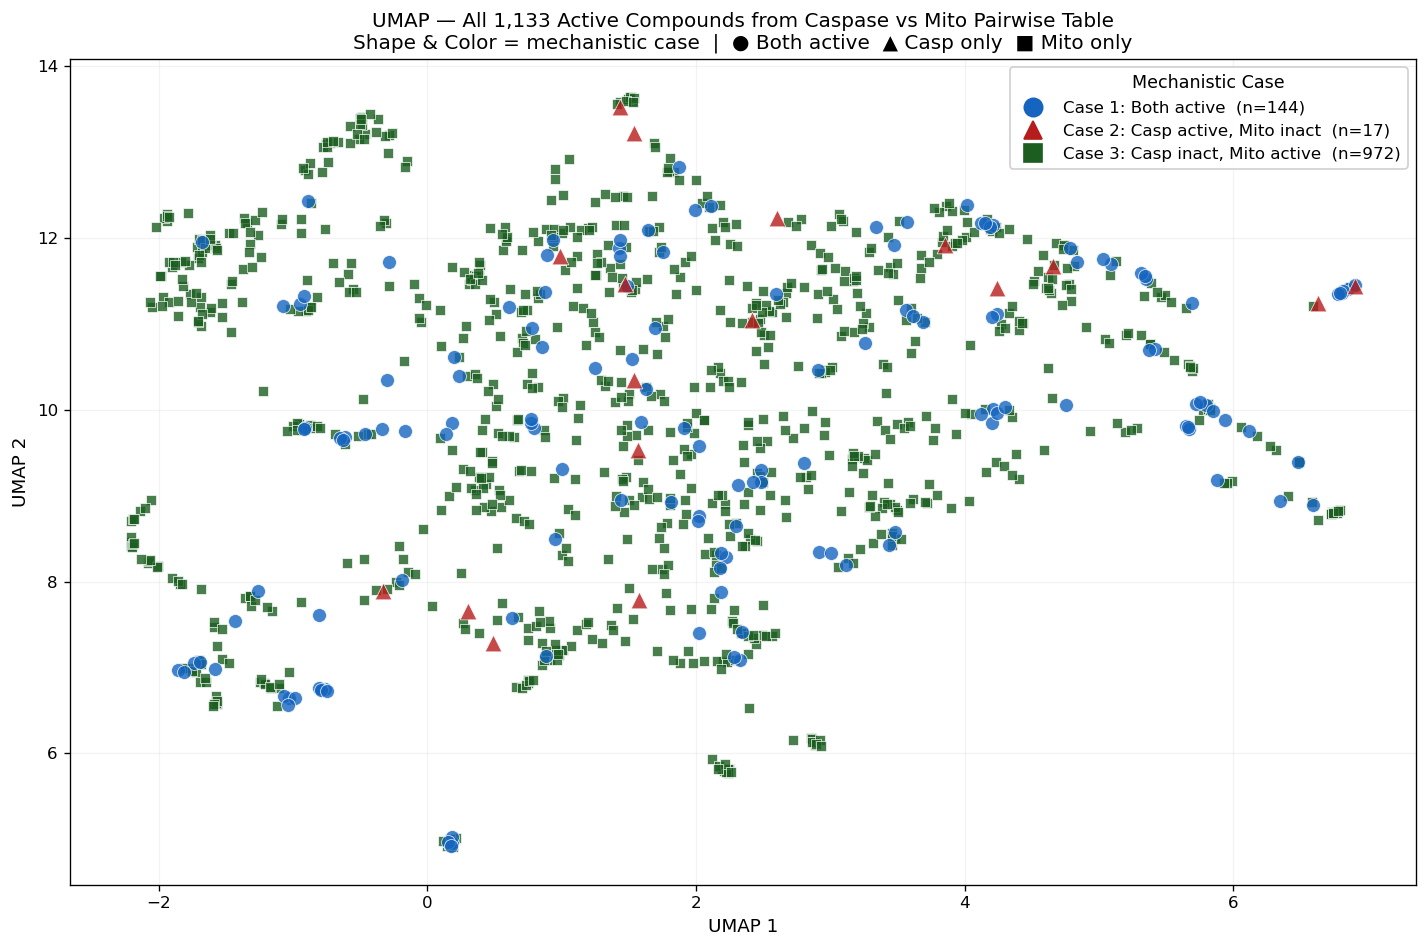

Saved: casp_mito_all_umap_cases.png


In [9]:
fig, ax = plt.subplots(figsize=(12, 8))

case_sizes = {'Case 1': 70, 'Case 2': 100, 'Case 3': 35}  # bigger for small-n cases

for label, desc, marker, color, _ in CASES:
    mask = valid_labels == label
    n    = mask.sum()
    if n == 0:
        continue
    ax.scatter(
        embedding[mask, 0], embedding[mask, 1],
        marker=marker, color=color,
        s=case_sizes[label],
        alpha=0.80, linewidths=0.5, edgecolors='white',
        zorder=4 if label == 'Case 2' else 3 if label == 'Case 1' else 2,
        label=f'{label}: {desc}  (n={n})',
    )

ax.set_title(
    'UMAP — All 1,133 Active Compounds from Caspase vs Mito Pairwise Table\n'
    'Shape & Color = mechanistic case  |  '
    '● Both active  ▲ Casp only  ■ Mito only',
    fontsize=12
)
ax.set_xlabel('UMAP 1', fontsize=11)
ax.set_ylabel('UMAP 2', fontsize=11)
ax.grid(True, alpha=0.15)

handles = [
    mlines.Line2D([0],[0], marker=marker, color=color, linestyle='None',
                  markersize=11, label=f'{label}: {desc}  (n={(valid_labels==label).sum()})')
    for label, desc, marker, color, _ in CASES
    if (valid_labels == label).sum() > 0
]
ax.legend(handles=handles, title='Mechanistic Case',
          loc='best', fontsize=10, title_fontsize=10.5,
          framealpha=0.92)

plt.tight_layout()
plt.savefig(
    '/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casp_mito_all_umap_cases.png',
    dpi=150, bbox_inches='tight'
)
plt.show()
print('Saved: casp_mito_all_umap_cases.png')

## Step 9 — Figure B: UMAP colored by DBSCAN cluster (shape=case retained)

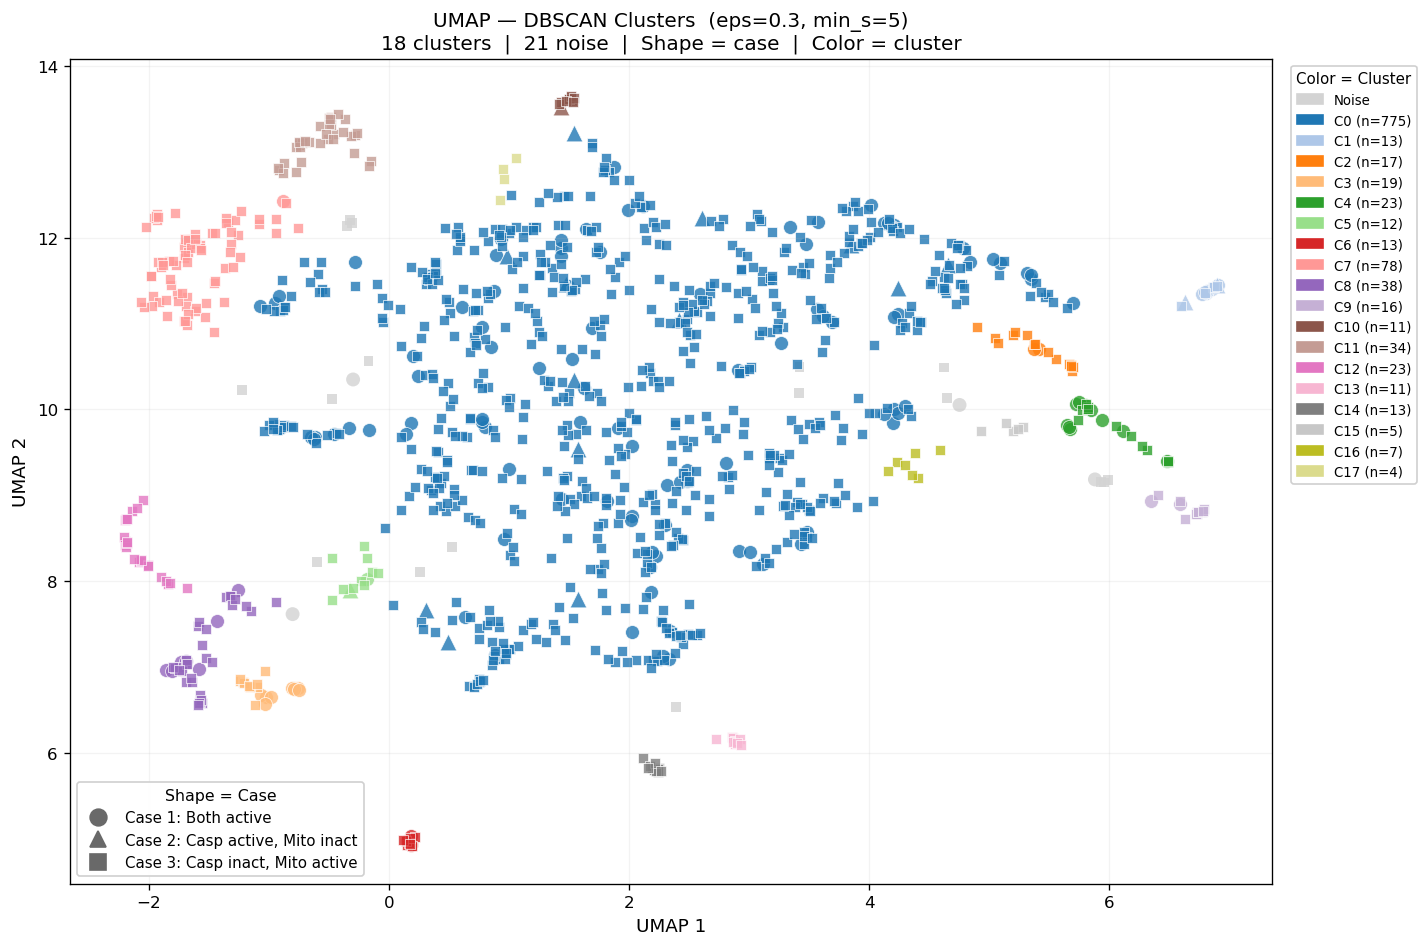

Saved: casp_mito_all_umap_dbscan.png


In [10]:
cmap_db     = plt.cm.tab20
cluster_ids = sorted(set(db_labels))
case_marker_map = {label: (marker, color)
                   for label, _, marker, color, _ in CASES}

fig, ax = plt.subplots(figsize=(12, 8))

for cl in cluster_ids:
    cl_color = 'lightgrey' if cl == -1 else cmap_db(cl % 20)
    for label, desc, case_mkr, _, _ in CASES:
        sub = (db_labels == cl) & (valid_labels == label)
        if sub.sum() == 0:
            continue
        ax.scatter(
            embedding[sub, 0], embedding[sub, 1],
            marker=case_mkr, color=cl_color,
            s=case_sizes[label],
            alpha=0.80, linewidths=0.5,
            edgecolors='white' if cl != -1 else 'none',
            label=(f'C{cl} (n={(db_labels==cl).sum()})' if cl != -1 else 'Noise')
                  if label == 'Case 1' else '_nolegend_',
        )

ax.set_title(
    f'UMAP — DBSCAN Clusters  (eps={EPS}, min_s={MIN_SAMPLES})\n'
    f'{n_clusters} clusters  |  {n_noise} noise  |  Shape = case  |  Color = cluster',
    fontsize=12
)
ax.set_xlabel('UMAP 1', fontsize=11)
ax.set_ylabel('UMAP 2', fontsize=11)
ax.grid(True, alpha=0.15)

# Shape legend (case)
sh = [
    mlines.Line2D([0],[0], marker=marker, color='dimgrey', linestyle='None',
                  markersize=10, label=f'{label}: {desc}')
    for label, desc, marker, color, _ in CASES
    if (valid_labels == label).sum() > 0
]
leg1 = ax.legend(handles=sh, title='Shape = Case',
                 loc='lower left', fontsize=9, title_fontsize=9.5, framealpha=0.92)
ax.add_artist(leg1)

# Cluster color legend
cl_h = [
    mpatches.Patch(
        color='lightgrey' if cl == -1 else cmap_db(cl % 20),
        label='Noise' if cl == -1 else f'C{cl} (n={(db_labels==cl).sum()})'
    )
    for cl in cluster_ids
]
ax.legend(handles=cl_h, title='Color = Cluster',
          bbox_to_anchor=(1.01, 1), loc='upper left',
          fontsize=8, title_fontsize=9, framealpha=0.92)

plt.tight_layout()
plt.savefig(
    '/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casp_mito_all_umap_dbscan.png',
    dpi=150, bbox_inches='tight'
)
plt.show()
print('Saved: casp_mito_all_umap_dbscan.png')

## Step 10 — Figure C: Side-by-side panel

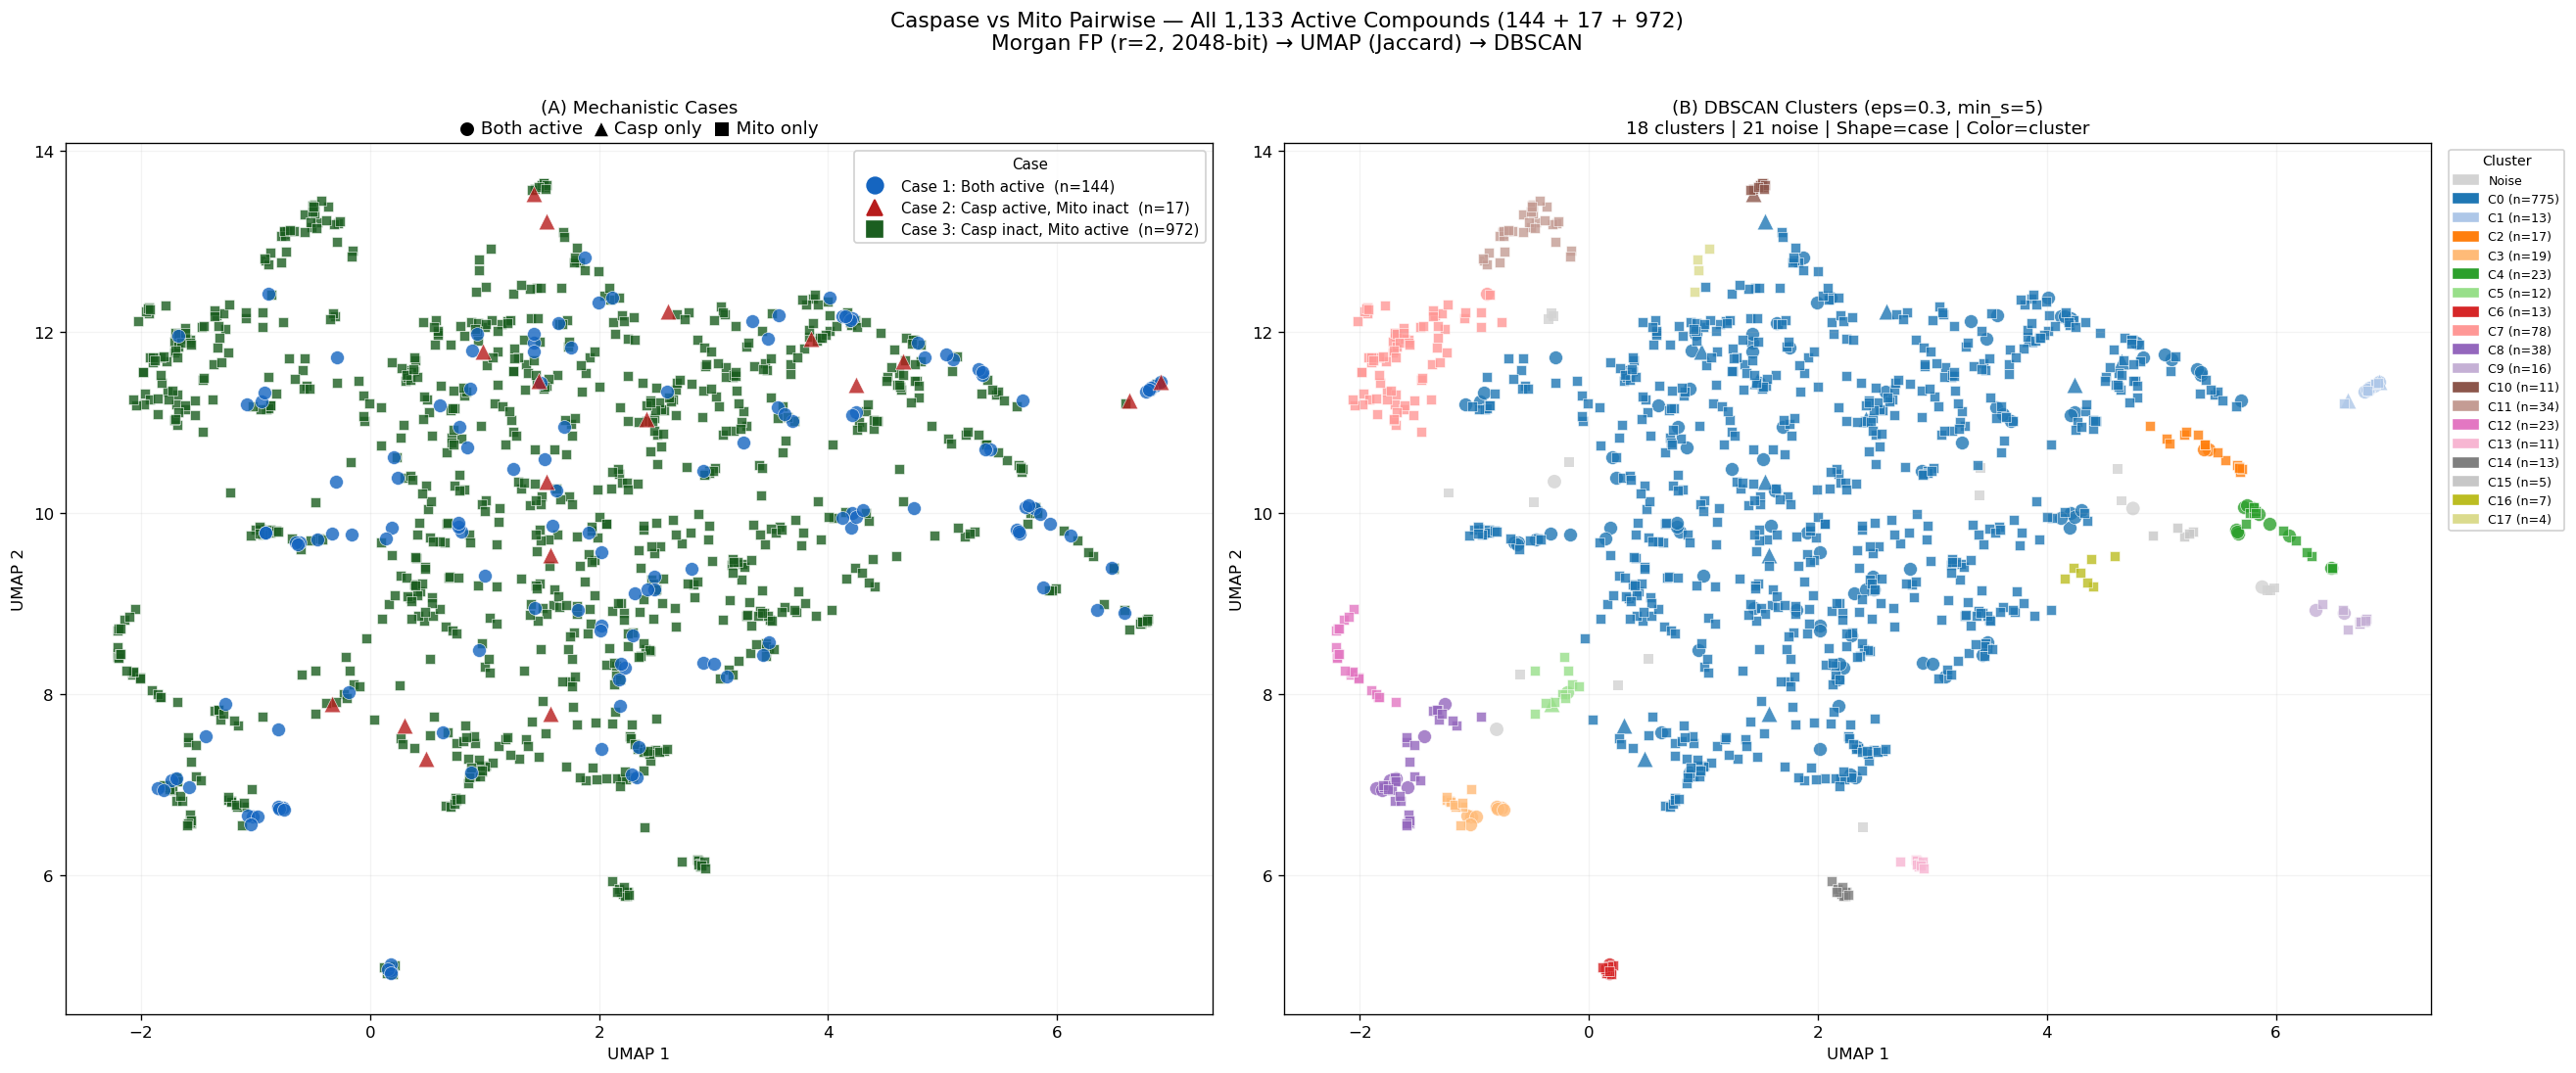

Saved: casp_mito_all_panel.png


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(22, 9))

# Left: mechanistic cases
ax1 = axes[0]
for label, desc, marker, color, _ in CASES:
    mask = valid_labels == label
    if mask.sum() == 0:
        continue
    ax1.scatter(embedding[mask,0], embedding[mask,1],
                marker=marker, color=color,
                s=case_sizes[label], alpha=0.80,
                linewidths=0.4, edgecolors='white',
                zorder=4 if label=='Case 2' else 3 if label=='Case 1' else 2)
ax1.set_title('(A) Mechanistic Cases\n● Both active  ▲ Casp only  ■ Mito only', fontsize=11)
ax1.set_xlabel('UMAP 1'); ax1.set_ylabel('UMAP 2')
ax1.grid(True, alpha=0.15)
sh = [mlines.Line2D([0],[0], marker=mkr, color=col, linestyle='None',
                    markersize=10, label=f'{lbl}: {dsc}  (n={(valid_labels==lbl).sum()})')
      for lbl, dsc, mkr, col, _ in CASES if (valid_labels==lbl).sum()>0]
ax1.legend(handles=sh, title='Case', loc='best',
           fontsize=9, title_fontsize=9, framealpha=0.90)

# Right: DBSCAN
ax2 = axes[1]
for cl in cluster_ids:
    cl_color = 'lightgrey' if cl == -1 else cmap_db(cl % 20)
    for label, desc, case_mkr, _, _ in CASES:
        sub = (db_labels == cl) & (valid_labels == label)
        if sub.sum() == 0:
            continue
        ax2.scatter(embedding[sub,0], embedding[sub,1],
                    marker=case_mkr, color=cl_color,
                    s=case_sizes[label], alpha=0.80,
                    linewidths=0.4, edgecolors='white' if cl!=-1 else 'none')
ax2.set_title(f'(B) DBSCAN Clusters (eps={EPS}, min_s={MIN_SAMPLES})\n'
              f'{n_clusters} clusters | {n_noise} noise | Shape=case | Color=cluster', fontsize=11)
ax2.set_xlabel('UMAP 1'); ax2.set_ylabel('UMAP 2')
ax2.grid(True, alpha=0.15)
cl_h = [mpatches.Patch(color='lightgrey' if cl==-1 else cmap_db(cl%20),
                        label='Noise' if cl==-1 else f'C{cl} (n={(db_labels==cl).sum()})')
        for cl in cluster_ids]
ax2.legend(handles=cl_h, title='Cluster', bbox_to_anchor=(1.01,1), loc='upper left',
           fontsize=7.5, title_fontsize=8.5, framealpha=0.9)

plt.suptitle(
    'Caspase vs Mito Pairwise — All 1,133 Active Compounds (144 + 17 + 972)\n'
    'Morgan FP (r=2, 2048-bit) → UMAP (Jaccard) → DBSCAN',
    fontsize=13, y=1.01
)
plt.tight_layout()
plt.savefig(
    '/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casp_mito_all_panel.png',
    dpi=150, bbox_inches='tight'
)
plt.show()
print('Saved: casp_mito_all_panel.png')

## Step 11 — Cluster composition: is mechanism structure-driven?

For each DBSCAN cluster, compute the fraction of each case.  
- **Pure cluster (one case > 80%)** → structure predicts mechanism  
- **Mixed cluster** → mechanism is context/dose-dependent, not structural

In [12]:
df_res = pd.DataFrame({
    'CID':    valid_cids,
    'Case':   valid_labels,
    'DBSCAN': db_labels,
    'UMAP1':  embedding[:, 0],
    'UMAP2':  embedding[:, 1],
})

# Composition matrix: cluster × case
comp = df_res.groupby(['DBSCAN', 'Case']).size().unstack(fill_value=0)
comp.index = ['Noise' if i == -1 else f'C{i}' for i in comp.index]
comp['Total'] = comp.sum(axis=1)
for case_lbl in ['Case 1', 'Case 2', 'Case 3']:
    if case_lbl in comp.columns:
        comp[f'{case_lbl}_%'] = (comp[case_lbl] / comp['Total'] * 100).round(1)

print('Cluster composition (n and % per case):')
print(comp.to_string())

# Enrichment summary
print('\nEnrichment summary:')
print(f'{'Cluster':10s}  {'n':>5s}  {'Dominant case':8s}  {'%':>6s}  Verdict')
print('─' * 65)
case_desc = {label: desc for label, desc, *_ in CASES}
for cl in sorted(set(db_labels)):
    sub = df_res[df_res['DBSCAN'] == cl]
    if len(sub) < 3:
        continue
    top  = sub['Case'].value_counts()
    dom  = top.index[0]
    frac = top.iloc[0] / len(sub)
    cl_nm = 'Noise' if cl == -1 else f'Cluster {cl}'
    if frac > 0.80:
        verdict = '*** PURE — structure predicts mechanism'
    elif frac > 0.60:
        verdict = '  * ENRICHED'
    else:
        verdict = '    MIXED — mechanism is context-driven'
    print(f'{cl_nm:10s}  {len(sub):>5d}  {dom:8s}  {frac:>5.0%}  {verdict}')

# Overall mixing score
n_mixed = sum(1 for cl in set(db_labels) if cl != -1
              and df_res[df_res['DBSCAN']==cl]['Case'].value_counts().iloc[0] /
                  len(df_res[df_res['DBSCAN']==cl]) < 0.6)
print(f'\nMixed clusters (dominant case <60%): {n_mixed} / {n_clusters}')

df_res.to_csv(
    '/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casp_mito_all_cluster_assignments.csv',
    index=False
)
print('Saved: casp_mito_all_cluster_assignments.csv')

Cluster composition (n and % per case):
Case   Case 1  Case 2  Case 3  Total  Case 1_%  Case 2_%  Case 3_%
Noise       4       0      17     21      19.0       0.0      81.0
C0         97      13     665    775      12.5       1.7      85.8
C1          6       2       5     13      46.2      15.4      38.5
C2          2       0      15     17      11.8       0.0      88.2
C3          9       0      10     19      47.4       0.0      52.6
C4         10       0      13     23      43.5       0.0      56.5
C5          1       1      10     12       8.3       8.3      83.3
C6          4       0       9     13      30.8       0.0      69.2
C7          2       0      76     78       2.6       0.0      97.4
C8          7       0      31     38      18.4       0.0      81.6
C9          2       0      14     16      12.5       0.0      87.5
C10         0       1      10     11       0.0       9.1      90.9
C11         0       0      34     34       0.0       0.0     100.0
C12         0       0 

## Step 12 — Stacked bar chart: case composition per cluster

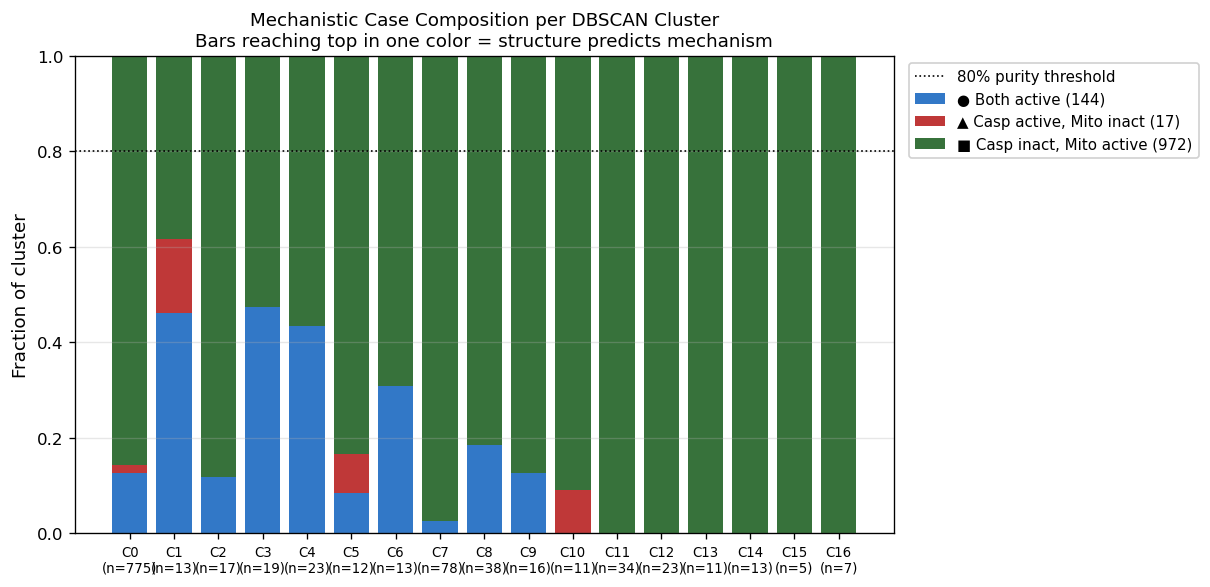

Saved: casp_mito_all_cluster_composition_bar.png


In [13]:
# Show only non-noise clusters with ≥5 members
plot_clusters = [cl for cl in sorted(set(db_labels))
                 if cl != -1 and (db_labels == cl).sum() >= 5]

case_colors_bar = {'Case 1': '#1565C0', 'Case 2': '#B71C1C', 'Case 3': '#1B5E20'}
case_labels_bar = {'Case 1': '● Both active (144)',
                   'Case 2': '▲ Casp active, Mito inact (17)',
                   'Case 3': '■ Casp inact, Mito active (972)'}

fig, ax = plt.subplots(figsize=(max(10, len(plot_clusters)*0.6), 5))

x     = np.arange(len(plot_clusters))
bottom = np.zeros(len(plot_clusters))

for case_lbl, bar_color in case_colors_bar.items():
    vals = []
    for cl in plot_clusters:
        sub   = df_res[df_res['DBSCAN'] == cl]
        frac  = (sub['Case'] == case_lbl).sum() / len(sub)
        vals.append(frac)
    vals = np.array(vals)
    ax.bar(x, vals, bottom=bottom, color=bar_color,
           label=case_labels_bar[case_lbl], alpha=0.88)
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels([f'C{cl}\n(n={(db_labels==cl).sum()})' for cl in plot_clusters],
                   fontsize=8)
ax.set_ylabel('Fraction of cluster', fontsize=11)
ax.set_ylim(0, 1)
ax.axhline(0.8, color='black', linestyle=':', lw=1, label='80% purity threshold')
ax.set_title(
    'Mechanistic Case Composition per DBSCAN Cluster\n'
    'Bars reaching top in one color = structure predicts mechanism',
    fontsize=11
)
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9, framealpha=0.9)
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(
    '/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casp_mito_all_cluster_composition_bar.png',
    dpi=150, bbox_inches='tight'
)
plt.show()
print('Saved: casp_mito_all_cluster_composition_bar.png')